---
title: Opening Multiple NetCDF Files
authors:
  - alex_dunne
downloads:
  - file: ./beginners_guide.zip
    title: Download the guide (.zip)
thumbnail: https://github.com/21centuryweather/Weather-Change-Cookbook/blob/main/recipes/beginners_guide/section2.png?raw=true
---

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/21centuryweather/Weather-Change-Cookbook/binder-beginners_guide)	­

Often your data is split across many files — for example, one file per city, or one file per year or month. This is often done for data management/size reasons. Xarray can open and combine them in a single line.

In [2]:
import xarray as xr              # NetCDF & multi-dimensional data
from glob import glob            # global path directory

In [ ]:
# Download the data, it can take a few minutes
!python download_data.py

## Using a glob pattern to find files

In [3]:
# ending with a “/” directs your code to a folder
# *.nc means "every file ending in .nc" in that folder
files = glob("data/*.nc")

# if you only want certain named files e.g. “data/file2014.nc” & “data/file2015.nc” 
# but not “data/flowerpot.nc”, then use the start of the file name 
files = glob("data/IDE00326*.nc")

print(f"Found {len(files)} files:")
for f in files:
    print(f)

Found 3 files:
data/IDE00326.202412311920.nc
data/IDE00326.202412311900.nc
data/IDE00326.202412311940.nc


:::{note} Glob patterns: (`glob("*.nc")`)

A glob is a wildcard pattern. `*.nc` matches any file ending in .nc. You can also use patterns like `solar_*.nc` or `*_2020.nc` to be more specific.
:::

## Open and combine all files at once

In [ ]:
ds = xr.open_mfdataset(files, combine="nested")

# combine="nested"  → concatenates along a new or existing dimension
# combine="by_coords" → lets xarray figure out alignment automatically


:::{note} `xr.open_mfdataset(files, combine="nested")`

Opens and lazily combines many NetCDF files into one Dataset. 'Lazy' means the data is not loaded into memory until you actually need it — essential for large datasets.
:::

In this example, we combine the Himawari satellite data from 31/12/2024 from 19:00 to 19:50. 

## Your turn: selecting variables

Select one variable and inspect it. You can also plot it following the steps in [section 1: Read NetCDF files](/section-1).

**Click on the cells below to check your answers.**

In [6]:
ds

<xarray.Dataset> Size: 780MB
Dimensions:                     (time: 3, latitude: 1726, longitude: 2214)
Coordinates:
  * time                        (time) datetime64[ns] 24B 2024-12-31T19:00:00...
  * latitude                    (latitude) float32 7kB -44.5 -44.48 ... -10.0
  * longitude                   (longitude) float32 9kB 112.0 112.0 ... 156.3
Data variables:
    crs                         int32 4B -2147483647
    surface_global_irradiance   (time, latitude, longitude) float64 92MB dask.array<chunksize=(1, 20, 2214), meta=np.ndarray>
    direct_normal_irradiance    (time, latitude, longitude) float64 92MB dask.array<chunksize=(1, 20, 2214), meta=np.ndarray>
    surface_diffuse_irradiance  (time, latitude, longitude) float64 92MB dask.array<chunksize=(1, 20, 2214), meta=np.ndarray>
    quality_mask                (time, latitude, longitude) float64 92MB dask.array<chunksize=(1, 20, 2214), meta=np.ndarray>
    cloud_type                  (time, latitude, longitude) float32 46MB dask.array<chunksize=(1, 20, 2214), meta=np.ndarray>
    cloud_optical_depth         (time, latitude, longitude) float64 92MB dask.array<chunksize=(1, 20, 2214), meta=np.ndarray>
    solar_elevation             (time, latitude, longitude) float64 92MB dask.array<chunksize=(1, 20, 2214), meta=np.ndarray>
    solar_azimuth               (time, latitude, longitude) float64 92MB dask.array<chunksize=(1, 20, 2214), meta=np.ndarray>
    julian_date                 (time, latitude, longitude) float64 92MB dask.array<chunksize=(1, 20, 2214), meta=np.ndarray>
Attributes: (12/57)
    Conventions:                      CF-1.7
    Metadata_Conventions:             Unidata Dataset Discovery v1.0
    acknowledgment:                   The following acknowledgement is requir...
    cdm_data_type:                    grid
    comment:                          Solar radiation data derived from satel...
    contributor_name:                 Mines ParisTech; Commonwealth of Austra...
    ...                               ...
    date_created:                     20250325T030059Z
    bias_correction_applied:          1
    bias_correction_applied_meaning:  0: not applied; 1:applied
    quality:                          0
    quality_meaning:                  0: no_known_issues 1: known_issue 
    history:                          heliosat-4; post_process_p1s.py

(array([3810365.,       0.,       0.,       0.,       0.,       0.,
         565581.,  736053.,  270729., 1396399.]),
 array([0.        , 0.80000001, 1.60000002, 2.4000001 , 3.20000005,
        4.        , 4.80000019, 5.5999999 , 6.4000001 , 7.20000029,
        8.        ]),
 <BarContainer object of 10 artists>)

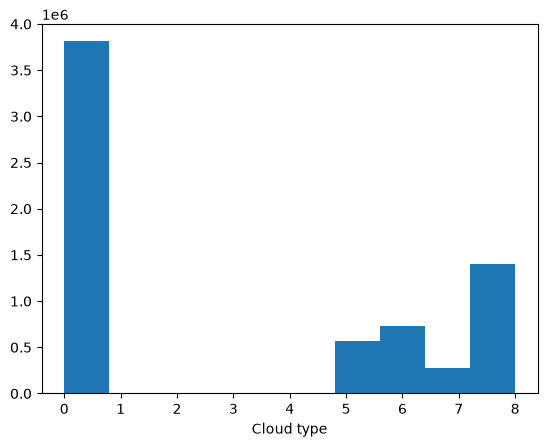

In [7]:
da_cldtyp = ds.cloud_type
da_cldtyp.plot()